# Imports

In [222]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import FunctionTransformer
from sklearn.base import BaseEstimator, TransformerMixin

# Load Dataset

In [223]:
# Load Titanic sample dataset
data = fetch_openml(name='titanic', version=1, as_frame=True)
df = data.frame

In [224]:
#describe numerical columns
df.describe()

,pclass,age,sibsp,parch,fare,body
count,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000,121.000000
mean,2.294882,29.881135,0.498854,0.385027,33.295479,160.809917
std,0.837836,14.413500,1.041658,0.865560,51.758668,97.696922
min,1.000000,0.166700,0.000000,0.000000,0.000000,1.000000
25%,2.000000,21.000000,0.000000,0.000000,7.895800,72.000000
50%,3.000000,28.000000,0.000000,0.000000,14.454200,155.000000
75%,3.000000,39.000000,1.000000,0.000000,31.275000,256.000000
max,3.000000,80.000000,8.000000,9.000000,512.329200,328.000000


In [225]:
#describe categorical columns
df.describe(include=['O'])

,name,ticket,cabin,boat,home.dest
count,1309,1309,295,486,745
unique,1307,929,186,27,369
top,"Connolly, Miss. Kate",CA. 2343,C23 C25 C27,13,"New York, NY"
freq,2,11,6,39,64


# Structure Dataset

In [226]:
# Separate features and target
X = df.drop(columns='survived')
y = df['survived']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Separate numeric and categorical columns
numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X_train.select_dtypes(include=['object', 'category']).columns

# Define Outlier Remover Class
Applying this class, outlier should be identified based on the IQR and directly be replaced by a lower percentila and upper percentile of choice

In [227]:
# Custom transformer for outlier handling
class OutlierRemover(BaseEstimator, TransformerMixin):
    def __init__(self,lower_percentile=0.05,upper_percentile=0.95):
        self.lower_percentile = lower_percentile
        self.upper_percentile = upper_percentile
    
    def fit(self, X, y=None):
        return self
    
    def transform(self, X, y=None):
        X = X.copy()
        for column in X.columns:
            Q1 = X[column].quantile(0.25)
            Q3 = X[column].quantile(0.75)
            IQR = Q3 - Q1
            lower_p_value = X[column].quantile(self.lower_percentile / 100)
            upper_p_value = X[column].quantile(self.upper_percentile / 100)

            # Cap outliers
            X[column] = X[column].apply(
                lambda x: lower_p_value if x < (Q1 - 1.5 * IQR) else x
            )
            X[column] = X[column].apply(
                lambda x: upper_p_value if x > (Q3 + 1.5 * IQR) else x
            )
        return X
    
    

In [228]:
X_train_numeric=X_train[numeric_features]
X_train_numeric

,pclass,age,sibsp,parch,fare,body
772,3,17.0,0,0,7.8958,NaN
543,2,36.0,0,0,10.5000,NaN
289,1,18.0,0,2,79.6500,NaN
10,1,47.0,1,0,227.5250,124.0
147,1,NaN,0,0,42.4000,NaN
...,...,...,...,...,...,...
1095,3,NaN,0,0,7.6292,NaN
1130,3,18.0,0,0,7.7750,NaN
1294,3,28.5,0,0,16.1000,14.0
860,3,26.0,0,0,7.9250,NaN


In [229]:
#Test outlier remover class
outlier_remover = OutlierRemover(5,95)
X_train_numeric_no_outliers=outlier_remover.fit_transform(X_train_numeric)


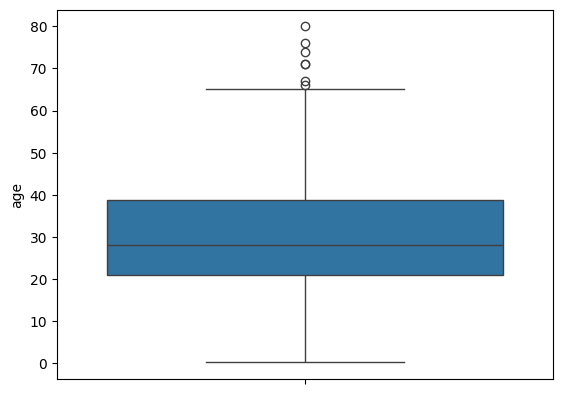

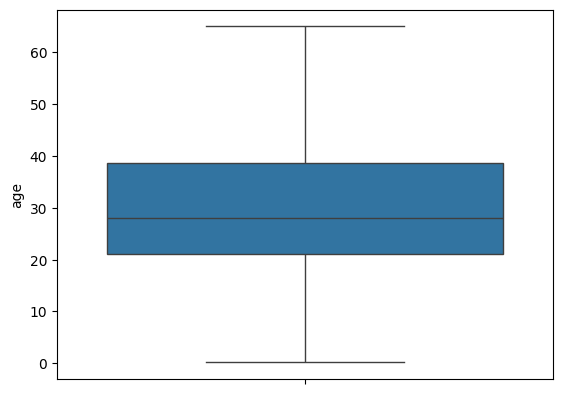

In [230]:
#draw boxplots for age and age_no_outlier using seaborn
import seaborn as sns
import matplotlib.pyplot as plt
sns.boxplot(y=X_train_numeric['age'],orient='v')
plt.show()
sns.boxplot(y=X_train_numeric_no_outliers['age'],orient='v')
plt.show()



# Define Pipeline 
### Pipeline for numeric features 

In [231]:
# Define preprocessing for numeric features 
numeric_transformer = Pipeline(steps=[
    ('outlier_remover', OutlierRemover(5,95)),     # Remove outliers
    ('imputer', SimpleImputer(strategy='median')),  # Handle missing values
    ('scaler', StandardScaler())                   # Standardize features
])

In [232]:
#Demonstrate application of numeric_transformer (Part1)
X_train_numeric

,pclass,age,sibsp,parch,fare,body
772,3,17.0,0,0,7.8958,NaN
543,2,36.0,0,0,10.5000,NaN
289,1,18.0,0,2,79.6500,NaN
10,1,47.0,1,0,227.5250,124.0
147,1,NaN,0,0,42.4000,NaN
...,...,...,...,...,...,...
1095,3,NaN,0,0,7.6292,NaN
1130,3,18.0,0,0,7.7750,NaN
1294,3,28.5,0,0,16.1000,14.0
860,3,26.0,0,0,7.9250,NaN


In [233]:
#Demonstrate application of numeric_transformer (Part2)
numeric_transformer.fit(X_train_numeric)
X_train_numeric_transformed = numeric_transformer.transform(X_train_numeric)
X_train_numeric_transformed = pd.DataFrame(X_train_numeric_transformed, columns=numeric_features)
X_train_numeric_transformed

,pclass,age,sibsp,parch,fare,body
0,0.840359,-0.971746,-0.652843,-0.558597,-0.618101,-0.015377
1,-0.355097,0.552215,-0.652843,-0.558597,-0.554509,-0.015377
2,-1.550554,-0.891538,-0.652843,1.790201,2.452676,-0.015377
3,-1.550554,1.434508,0.922104,-0.558597,2.452676,-1.077648
4,-1.550554,-0.089453,-0.652843,-0.558597,0.224453,-0.015377
...,...,...,...,...,...,...
1042,0.840359,-0.089453,-0.652843,-0.558597,-0.624611,-0.015377
1043,0.840359,-0.891538,-0.652843,-0.558597,-0.621051,-0.015377
1044,0.840359,-0.049349,-0.652843,-0.558597,-0.417763,-4.729206
1045,0.840359,-0.249870,-0.652843,-0.558597,-0.617388,-0.015377


### Pipeline for categoric features

In [234]:
# Define preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),  # Handle missing values
    ('onehot', OneHotEncoder(handle_unknown='ignore'))     # One-hot encoding
])

In [235]:
#Demonstrate application of categorical_transformer (Part1)
X_train_categorical = X_train[categorical_features]
X_train_categorical

,name,sex,ticket,cabin,embarked,boat,home.dest
772,"Dika, Mr. Mirko",male,349232,NaN,S,NaN,NaN
543,"Reeves, Mr. David",male,C.A. 17248,NaN,S,NaN,"Brighton, Sussex"
289,"Taussig, Miss. Ruth",female,110413,E68,S,8,"New York, NY"
10,"Astor, Col. John Jacob",male,PC 17757,C62 C64,C,NaN,"New York, NY"
147,"Harrington, Mr. Charles H",male,113796,NaN,S,NaN,NaN
...,...,...,...,...,...,...,...
1095,"O'Sullivan, Miss. Bridget Mary",female,330909,NaN,Q,NaN,NaN
1130,"Pettersson, Miss. Ellen Natalia",female,347087,NaN,S,NaN,NaN
1294,"Williams, Mr. Leslie",male,54636,NaN,S,NaN,NaN
860,"Heikkinen, Miss. Laina",female,STON/O2. 3101282,NaN,S,NaN,NaN


In [236]:
#Remove name, ticket, cabin and home.dest columns from categorical features
X_train_categorical = X_train_categorical.drop(columns=['name','ticket','cabin','home.dest'])
X_train_categorical

reduced_categorical_features = X_train_categorical.columns

In [237]:
#Demonstrate application of categorical_transformer (Part2)
categorical_transformer.fit(X_train_categorical)
X_train_categorical_transformed = categorical_transformer.transform(X_train_categorical)
X_train_categorical_transformed = pd.DataFrame(X_train_categorical_transformed.toarray(), columns=categorical_transformer.get_feature_names_out())
X_train_categorical_transformed

,sex_female,sex_male,embarked_C,embarked_Q,embarked_S,boat_1,boat_10,boat_11,boat_12,boat_13,...,boat_6,boat_7,boat_8,boat_8 10,boat_9,boat_A,boat_B,boat_C,boat_C D,boat_D
0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1042,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1043,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1044,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1045,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# Combined Pipeline

In [238]:
# Combine preprocessors in a ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, reduced_categorical_features)
    ]
)

In [239]:
# Define the final pipeline
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))  # Classifier
])

# Train Pipeline

In [240]:
# Train the pipeline
pipeline.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('outlier_remover',
                                                                   OutlierRemover(lower_percentile=5,
                                                                                  upper_percentile=95)),
                                                                  ('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['pclass', 'age', 'sibsp', 'parch', 'fare', 'body'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['sex', 'embarked', 'boat'], dtype='object'))])),
                ('classifier', RandomForestClassifier(random_state=42))])

# Evaluate Pipeline

In [241]:
# Evaluate the pipeline
train_score = pipeline.score(X_train, y_train)
test_score = pipeline.score(X_test, y_test)

print(f"Training accuracy: {train_score:.2f}")
print(f"Testing accuracy: {test_score:.2f}")


Training accuracy: 0.99
Testing accuracy: 0.95
